# Functional projection and temporal turnover

Reproducible analysis of trophic-functional projections derived from realized taxonomic food webs, including temporal turnover and representation-specific null models. The cumulative functional projection is retained only as supplementary description.

In [1]:
# Shared configuration
from pathlib import Path
import os

# Directory containing the audited input CSV files.
# Set FOODWEB_DATA_DIR to use a different location without editing the notebook.
DATA_DIR = Path(os.environ.get("FOODWEB_DATA_DIR", ".")).resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
print(f"Data/output directory: {DATA_DIR}")


Data/output directory: /content


## 1. Project realized taxonomic networks onto trophic-functional categories

Generate functional projections directly from realized taxonomic interactions for each sampling event. Multiple taxonomic interactions mapping to the same functional pair are collapsed to a single binary link; within-category interactions are retained for traceability.

In [2]:
"""
Functional food web — Stage 1 v2
Projection of the audited taxonomic networks onto trophic-functional categories

This script CONSTRUCTS and AUDITS the definitive functional projection.
It does not calculate final network metrics or null models yet.

Canonical direction throughout: resource -> consumer.

Inputs
------
FW_lagoon_nodes_AUDITED.csv
FW_lagoon_trophic_links_AUDITED.csv
FW_lagoon_food_web_by_sampling_AUDITED.csv
FW_lagoon_functional_links_AUDITED.csv

Outputs include:
- cumulative projected functional network
- 16 temporal projected functional networks
- taxonomic-to-functional edge traceability
- within-category interaction audit (functional self-loops)
- comparison with the historical curated functional edge list
"""

from pathlib import Path
import pandas as pd
import networkx as nx

# Colab first; /mnt/data fallback makes the same script runnable in ChatGPT's environment.
BASE = DATA_DIR

NODES_FILE = BASE / "FW_lagoon_nodes_AUDITED.csv"
TROPHIC_FILE = BASE / "FW_lagoon_trophic_links_AUDITED.csv"
SAMPLING_FILE = BASE / "FW_lagoon_food_web_by_sampling_AUDITED.csv"
HISTORICAL_FUNCTIONAL_FILE = BASE / "FW_lagoon_functional_links_AUDITED.csv"

TEMPORAL_DATES = [
    "14/05/2016","09/07/2016","10/09/2016","20/01/2017",
    "16/03/2017","06/04/2017","29/06/2017","08/09/2017",
    "15/11/2017","23/12/2017","23/02/2018","19/05/2018",
    "11/08/2018","20/10/2018","09/03/2019","01/06/2019",
]

def clean(x):
    if pd.isna(x):
        return None
    x = str(x).strip()
    return x if x else None

def require_files(paths):
    missing = [p.name for p in paths if not p.exists()]
    if missing:
        raise FileNotFoundError(
            "Missing required input file(s): "
            + ", ".join(missing)
            + f"\nCurrent BASE is {BASE}. In Colab, upload them to /content."
        )

def load_inputs():
    require_files([NODES_FILE, TROPHIC_FILE, SAMPLING_FILE])

    nodes = pd.read_csv(NODES_FILE)
    trophic = pd.read_csv(TROPHIC_FILE)
    sampling = pd.read_csv(SAMPLING_FILE)

    req_nodes = {"node", "category"}
    req_trophic = {"consumer", "resource"}
    if not req_nodes.issubset(nodes.columns):
        raise ValueError(f"Missing node columns: {req_nodes - set(nodes.columns)}")
    if not req_trophic.issubset(trophic.columns):
        raise ValueError(f"Missing trophic columns: {req_trophic - set(trophic.columns)}")

    for c in ["node", "category"]:
        nodes[c] = nodes[c].map(clean)
    for c in ["consumer", "resource"]:
        trophic[c] = trophic[c].map(clean)

    if nodes["node"].duplicated().any():
        raise ValueError("Duplicate taxonomic nodes in audited node table.")
    if nodes["node"].isna().any() or nodes["category"].isna().any():
        raise ValueError("Missing node/category values in audited node table.")
    if trophic[["consumer","resource"]].isna().any().any():
        raise ValueError("Missing consumer/resource values in audited trophic-link table.")
    if trophic.duplicated(["consumer","resource"]).any():
        raise ValueError("Duplicate taxonomic trophic links in audited table.")

    valid_taxa = set(nodes["node"])
    endpoints = set(trophic["consumer"]) | set(trophic["resource"])
    unknown = sorted(endpoints - valid_taxa)
    if unknown:
        raise ValueError(f"Trophic endpoints absent from audited nodes: {unknown}")

    missing_dates = [d for d in TEMPORAL_DATES if d not in sampling.columns]
    if missing_dates:
        raise ValueError(f"Temporal dates missing from sampling table: {missing_dates}")

    historical = None
    if HISTORICAL_FUNCTIONAL_FILE.exists():
        historical = pd.read_csv(HISTORICAL_FUNCTIONAL_FILE)
        if not {"source","target"}.issubset(historical.columns):
            raise ValueError("Historical functional file must contain source,target.")
        historical["source"] = historical["source"].map(clean)
        historical["target"] = historical["target"].map(clean)

    return nodes, trophic, sampling, historical

def observed_taxa(sampling, date, valid_taxa):
    vals = {clean(x) for x in sampling[date].dropna().tolist()}
    vals.discard(None)
    unknown = sorted(vals - valid_taxa)
    if unknown:
        raise ValueError(f"{date}: taxa absent from audited node table: {unknown}")
    return vals

def graph_audit(G):
    return {
        "S_functional": G.number_of_nodes(),
        "L_functional_including_self_loops": G.number_of_edges(),
        "n_self_loops": nx.number_of_selfloops(G),
        "L_between_categories": G.number_of_edges() - nx.number_of_selfloops(G),
        "n_isolates": len(list(nx.isolates(G))),
        "weak_components": nx.number_weakly_connected_components(G) if G.number_of_nodes() else 0,
        "strong_components": nx.number_strongly_connected_components(G) if G.number_of_nodes() else 0,
        # A self-loop makes NetworkX report non-DAG. Also report DAG after removing loops.
        "is_DAG_including_self_loops": nx.is_directed_acyclic_graph(G),
        "is_DAG_after_removing_self_loops": nx.is_directed_acyclic_graph(
            nx.DiGraph([(u,v) for u,v in G.edges() if u != v])
        ),
    }

def project_taxonomic_edges(trophic_subset, node_to_cat):
    """
    Project taxonomic resource->consumer interactions to category resource->consumer.
    Input table is stored consumer,resource.
    Returns:
      projected unique functional edges
      taxonomic->functional traceability table
    """
    rows = []
    for r in trophic_subset.itertuples(index=False):
        resource_cat = node_to_cat[r.resource]
        consumer_cat = node_to_cat[r.consumer]
        rows.append({
            "taxonomic_resource": r.resource,
            "taxonomic_consumer": r.consumer,
            "resource_category": resource_cat,
            "consumer_category": consumer_cat,
            "within_category_interaction": resource_cat == consumer_cat,
        })
    trace = pd.DataFrame(rows)

    if trace.empty:
        projected = pd.DataFrame(columns=[
            "resource_category","consumer_category","within_category_interaction",
            "n_taxonomic_links_supporting","taxonomic_links_supporting"
        ])
        return projected, trace

    grouped = (
        trace.groupby(
            ["resource_category","consumer_category","within_category_interaction"],
            as_index=False
        )
        .agg(
            n_taxonomic_links_supporting=("taxonomic_resource","size"),
            taxonomic_links_supporting=(
                "taxonomic_resource",
                lambda _: ""  # filled below to preserve resource-consumer pairs
            ),
        )
    )

    support_map = (
        trace.assign(
            pair=trace["taxonomic_resource"] + " -> " + trace["taxonomic_consumer"]
        )
        .groupby(["resource_category","consumer_category"])["pair"]
        .apply(lambda x: " | ".join(sorted(x)))
        .to_dict()
    )
    grouped["taxonomic_links_supporting"] = [
        support_map[(r.resource_category, r.consumer_category)]
        for r in grouped.itertuples(index=False)
    ]

    return grouped, trace

def historical_comparison(projected, historical):
    if historical is None:
        return None
    # historical source=consumer, target=resource -> canonical resource->consumer
    old = set(zip(historical["target"], historical["source"]))
    new = set(zip(projected["resource_category"], projected["consumer_category"]))
    rows = []
    for edge in sorted(old | new):
        rows.append({
            "resource_category": edge[0],
            "consumer_category": edge[1],
            "in_historical_curated": edge in old,
            "in_projected_from_taxonomic": edge in new,
            "status": (
                "both" if edge in old and edge in new
                else "historical_only" if edge in old
                else "projected_only"
            )
        })
    return pd.DataFrame(rows)

def main():
    nodes, trophic, sampling, historical = load_inputs()
    valid_taxa = set(nodes["node"])
    node_to_cat = dict(zip(nodes["node"], nodes["category"]))
    all_categories = sorted(nodes["category"].unique())

    print("INPUT AUDIT")
    print(f"Audited taxonomic nodes: {len(nodes)}")
    print(f"Audited taxonomic links: {len(trophic)}")
    print(f"Functional categories: {len(all_categories)}")
    print(f"Complete temporal dates: {len(TEMPORAL_DATES)}")
    print(f"Historical functional table available: {historical is not None}")

    # ---------- cumulative projection ----------
    projected_master, trace_master = project_taxonomic_edges(trophic, node_to_cat)

    G = nx.DiGraph()
    G.add_nodes_from(all_categories)
    G.add_edges_from(
        projected_master[["resource_category","consumer_category"]]
        .itertuples(index=False, name=None)
    )
    cumulative_audit = graph_audit(G)

    print("\nCUMULATIVE PROJECTED FUNCTIONAL NETWORK")
    for k,v in cumulative_audit.items():
        print(f"{k}: {v}")

    projected_master.to_csv(
        BASE / "functional_projected_complete_edges_stage1_v2.csv", index=False
    )
    trace_master.to_csv(
        BASE / "functional_taxonomic_edge_traceability_complete_stage1_v2.csv", index=False
    )
    pd.DataFrame([cumulative_audit]).to_csv(
        BASE / "functional_projected_complete_audit_stage1_v2.csv", index=False
    )

    loops = projected_master[projected_master["within_category_interaction"]].copy()
    loops.to_csv(
        BASE / "functional_within_category_interactions_complete_stage1_v2.csv",
        index=False
    )

    print("\nWITHIN-CATEGORY FUNCTIONAL INTERACTIONS")
    if loops.empty:
        print("None")
    else:
        print(
            loops[
                ["resource_category","consumer_category",
                 "n_taxonomic_links_supporting","taxonomic_links_supporting"]
            ].to_string(index=False)
        )

    # Historical comparison is diagnostic only.
    comp = historical_comparison(projected_master, historical)
    if comp is not None:
        comp.to_csv(
            BASE / "functional_historical_vs_projected_stage1_v2.csv", index=False
        )
        print("\nHISTORICAL CURATED vs NEW TAXONOMIC PROJECTION")
        print(comp["status"].value_counts().to_string())
        discrep = comp[comp["status"] != "both"]
        if len(discrep):
            print("\nDiscrepant functional edges:")
            print(discrep.to_string(index=False))

    # ---------- temporal projections ----------
    temporal_audit = []
    temporal_projected_edges = []
    temporal_trace = []
    temporal_nodes = []
    temporal_loops = []

    for date in TEMPORAL_DATES:
        taxa_t = observed_taxa(sampling, date, valid_taxa)

        # Exact realized taxonomic graph rule used in structural analysis:
        # retain master taxonomic edges only when both endpoint taxa occur at t.
        trophic_t = trophic[
            trophic["consumer"].isin(taxa_t)
            & trophic["resource"].isin(taxa_t)
        ].copy()

        # Functional nodes are the categories represented by taxa observed at t,
        # including categories that may become isolates after edge filtering.
        cats_t = sorted({node_to_cat[x] for x in taxa_t})

        projected_t, trace_t = project_taxonomic_edges(trophic_t, node_to_cat)

        Gt = nx.DiGraph()
        Gt.add_nodes_from(cats_t)
        Gt.add_edges_from(
            projected_t[["resource_category","consumer_category"]]
            .itertuples(index=False, name=None)
        )

        a = graph_audit(Gt)
        a.update({
            "date": date,
            "n_taxa_observed": len(taxa_t),
            "L_taxonomic_realized": len(trophic_t),
            "n_functional_categories_present": len(cats_t),
        })
        temporal_audit.append(a)

        for cat in cats_t:
            members = sorted(x for x in taxa_t if node_to_cat[x] == cat)
            temporal_nodes.append({
                "date": date,
                "functional_category": cat,
                "n_taxa_present": len(members),
                "taxa_present": " | ".join(members),
                "is_functional_isolate": nx.is_isolate(Gt, cat),
            })

        if not projected_t.empty:
            p = projected_t.copy()
            p.insert(0, "date", date)
            temporal_projected_edges.append(p)

        if not trace_t.empty:
            tr = trace_t.copy()
            tr.insert(0, "date", date)
            temporal_trace.append(tr)

        lt = projected_t[projected_t["within_category_interaction"]].copy()
        if not lt.empty:
            lt.insert(0, "date", date)
            temporal_loops.append(lt)

    audit_df = pd.DataFrame(temporal_audit)
    audit_df = audit_df[
        ["date","n_taxa_observed","L_taxonomic_realized",
         "n_functional_categories_present","S_functional",
         "L_functional_including_self_loops","n_self_loops",
         "L_between_categories","n_isolates","weak_components",
         "strong_components","is_DAG_including_self_loops",
         "is_DAG_after_removing_self_loops"]
    ]
    audit_df.to_csv(
        BASE / "temporal_functional_projected_audit_stage1_v2.csv", index=False
    )

    pd.DataFrame(temporal_nodes).to_csv(
        BASE / "temporal_functional_projected_nodes_stage1_v2.csv", index=False
    )

    edges_df = (
        pd.concat(temporal_projected_edges, ignore_index=True)
        if temporal_projected_edges
        else pd.DataFrame()
    )
    edges_df.to_csv(
        BASE / "temporal_functional_projected_edges_stage1_v2.csv", index=False
    )

    trace_df = (
        pd.concat(temporal_trace, ignore_index=True)
        if temporal_trace else pd.DataFrame()
    )
    trace_df.to_csv(
        BASE / "temporal_functional_taxonomic_edge_traceability_stage1_v2.csv",
        index=False
    )

    loops_t_df = (
        pd.concat(temporal_loops, ignore_index=True)
        if temporal_loops else pd.DataFrame()
    )
    loops_t_df.to_csv(
        BASE / "temporal_functional_within_category_interactions_stage1_v2.csv",
        index=False
    )

    print("\nTEMPORAL PROJECTED FUNCTIONAL NETWORK AUDIT")
    print(audit_df.to_string(index=False))

    print("\nIMPORTANT")
    print(
        "Self-loops are retained at this construction/audit stage because they encode "
        "taxonomic feeding interactions between different taxa assigned to the same "
        "functional category. Do not calculate final connectance, trophic levels, "
        "community metrics, or null models from these graphs until the treatment of "
        "within-category interactions is explicitly decided."
    )

    print("\nFILES WRITTEN")
    outputs = [
        "functional_projected_complete_edges_stage1_v2.csv",
        "functional_taxonomic_edge_traceability_complete_stage1_v2.csv",
        "functional_projected_complete_audit_stage1_v2.csv",
        "functional_within_category_interactions_complete_stage1_v2.csv",
        "functional_historical_vs_projected_stage1_v2.csv",
        "temporal_functional_projected_audit_stage1_v2.csv",
        "temporal_functional_projected_nodes_stage1_v2.csv",
        "temporal_functional_projected_edges_stage1_v2.csv",
        "temporal_functional_taxonomic_edge_traceability_stage1_v2.csv",
        "temporal_functional_within_category_interactions_stage1_v2.csv",
    ]
    for f in outputs:
        if (BASE / f).exists():
            print(f)



In [3]:
main()

INPUT AUDIT
Audited taxonomic nodes: 75
Audited taxonomic links: 394
Functional categories: 14
Complete temporal dates: 16
Historical functional table available: True

CUMULATIVE PROJECTED FUNCTIONAL NETWORK
S_functional: 14
L_functional_including_self_loops: 35
n_self_loops: 2
L_between_categories: 33
n_isolates: 0
weak_components: 1
strong_components: 14
is_DAG_including_self_loops: False
is_DAG_after_removing_self_loops: True

WITHIN-CATEGORY FUNCTIONAL INTERACTIONS
  resource_category   consumer_category  n_taxonomic_links_supporting             taxonomic_links_supporting
gathering collector gathering collector                             1            Oligochaeta -> Chironomidae
           predator            predator                             1 Hydrophilidae larvae -> Belostomatidae

HISTORICAL CURATED vs NEW TAXONOMIC PROJECTION
status
both               31
projected_only      4
historical_only     3

Discrepant functional edges:
    resource_category   consumer_category  in_hi

## 2. Calculate observed functional-network metrics

Calculate descriptive metrics for the temporal functional projections and the cumulative functional projection.

In [4]:
"""
Functional food web — Stage 2
Observed metrics + cumulative functional-network figure

Analytical definition
---------------------
The functional network is the projection of the audited realized taxonomic network
onto trophic-functional categories.

Canonical direction: resource -> consumer.

Within-category taxonomic interactions are retained in the Stage 1 traceability
outputs, but functional self-loops are EXCLUDED from topology metrics because they
are created by aggregation of distinct taxa into the same functional category.

This script calculates:
1) observed metrics for the cumulative functional projection;
2) observed metrics for the 16 temporal functional projections;
3) cumulative node-level trophic information;
4) a publication-ready cumulative functional-network figure (PNG + PDF).

No null models are calculated here.
"""

from pathlib import Path
import math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

SEED = 12345
INFOMAP_TRIALS = 20

BASE = DATA_DIR

COMPLETE_EDGES = BASE / "functional_projected_complete_edges_stage1_v2.csv"
COMPLETE_AUDIT = BASE / "functional_projected_complete_audit_stage1_v2.csv"
TEMPORAL_EDGES = BASE / "temporal_functional_projected_edges_stage1_v2.csv"
TEMPORAL_NODES = BASE / "temporal_functional_projected_nodes_stage1_v2.csv"
TEMPORAL_AUDIT = BASE / "temporal_functional_projected_audit_stage1_v2.csv"
COMPLETE_TRACE = BASE / "functional_taxonomic_edge_traceability_complete_stage1_v2.csv"

TEMPORAL_DATES = [
    "14/05/2016","09/07/2016","10/09/2016","20/01/2017",
    "16/03/2017","06/04/2017","29/06/2017","08/09/2017",
    "15/11/2017","23/12/2017","23/02/2018","19/05/2018",
    "11/08/2018","20/10/2018","09/03/2019","01/06/2019",
]

def require_files(paths):
    missing = [p.name for p in paths if not p.exists()]
    if missing:
        raise FileNotFoundError(
            "Missing Stage 1 v2 output(s): " + ", ".join(missing) +
            f"\nBASE = {BASE}\nRun functional_network_projection_stage1_v2.ipynb first."
        )

def directed_modularity(G, communities):
    """Leicht-Newman directed modularity Q for a supplied partition."""
    m = G.number_of_edges()
    if m == 0 or not communities:
        return np.nan
    within = sum(
        1.0 for i, j in G.edges()
        if communities.get(i) == communities.get(j)
    )
    groups = {}
    for n, c in communities.items():
        groups.setdefault(c, []).append(n)
    expected = sum(
        sum(G.out_degree(n) for n in members) *
        sum(G.in_degree(n) for n in members) / m
        for members in groups.values()
    )
    return float((within - expected) / m)

def infomap_partition(G, seed=SEED, num_trials=INFOMAP_TRIALS):
    """Directed Infomap; same definition used in the structural pipeline."""
    try:
        from infomap import Infomap
    except ImportError:
        return None, {
            "n_modules": np.nan,
            "codelength": np.nan,
            "infomap_available": False,
        }

    if G.number_of_edges() == 0:
        # No meaningful flow partition for an edgeless graph.
        return None, {
            "n_modules": np.nan,
            "codelength": np.nan,
            "infomap_available": True,
        }

    im = Infomap(
        f"--directed --silent --seed {seed} --num-trials {num_trials}"
    )
    node_to_int = {n: i for i, n in enumerate(G.nodes())}
    int_to_node = {i: n for n, i in node_to_int.items()}

    for u, v in G.edges():
        im.add_link(node_to_int[u], node_to_int[v])

    im.run()
    part = {int_to_node[x.node_id]: x.module_id for x in im.nodes}

    # Infomap may omit isolates from its flow solution. Give each omitted
    # isolate a unique module only for node accounting; Q is reported for
    # the resulting full partition.
    next_module = max(part.values(), default=0) + 1
    for n in G.nodes():
        if n not in part:
            part[n] = next_module
            next_module += 1

    return part, {
        "n_modules": len(set(part.values())),
        "codelength": float(im.codelength),
        "infomap_available": True,
    }

def prey_averaged_trophic_levels(G):
    """
    DAG prey-averaged trophic level:
    basal = 1
    consumer = 1 + mean(TL of resources)
    """
    if not nx.is_directed_acyclic_graph(G):
        return {n: np.nan for n in G.nodes()}

    tl = {}
    for n in nx.topological_sort(G):
        resources = list(G.predecessors(n))
        tl[n] = (
            1.0 if not resources
            else 1.0 + float(np.mean([tl[r] for r in resources]))
        )
    return tl

def omnivory_index(G, tl):
    out = {}
    for n in G.nodes():
        resources = list(G.predecessors(n))
        vals = [tl[r] for r in resources if np.isfinite(tl.get(r, np.nan))]
        if not np.isfinite(tl.get(n, np.nan)):
            out[n] = np.nan
        elif len(vals) >= 2:
            out[n] = float(np.std(vals, ddof=0))
        else:
            out[n] = 0.0
    return out

def chain_metrics(G):
    if not nx.is_directed_acyclic_graph(G):
        return {
            "max_chain_edges": np.nan,
            "mean_chain_edges": np.nan,
            "n_basal_terminal_paths": np.nan,
        }

    basal = [n for n in G if G.in_degree(n) == 0]
    top = [n for n in G if G.out_degree(n) == 0]
    lengths = []

    for b in basal:
        for t in top:
            if nx.has_path(G, b, t):
                lengths.extend(
                    len(path) - 1
                    for path in nx.all_simple_paths(G, b, t)
                )

    return {
        "max_chain_edges": max(lengths) if lengths else np.nan,
        "mean_chain_edges": float(np.mean(lengths)) if lengths else np.nan,
        "n_basal_terminal_paths": len(lengths),
    }

def calculate_metrics(G, seed=SEED):
    """
    Metrics are calculated on the loop-free between-category graph only.
    """
    if nx.number_of_selfloops(G) != 0:
        raise ValueError("Analytical functional graph contains self-loops.")

    S = G.number_of_nodes()
    L = G.number_of_edges()

    indeg = dict(G.in_degree())
    outdeg = dict(G.out_degree())
    totaldeg = dict(G.degree())

    basal = [n for n in G if indeg[n] == 0]
    top = [n for n in G if outdeg[n] == 0]
    intermediate = [
        n for n in G if indeg[n] > 0 and outdeg[n] > 0
    ]

    tl = prey_averaged_trophic_levels(G)
    oi = omnivory_index(G, tl)
    finite_tl = [x for x in tl.values() if np.isfinite(x)]
    finite_oi = [x for x in oi.values() if np.isfinite(x)]

    bet = nx.betweenness_centrality(G, normalized=True)
    close = nx.closeness_centrality(G)
    clustering = nx.clustering(G)

    try:
        assort = nx.degree_assortativity_coefficient(
            G, x="out", y="in"
        )
    except Exception:
        assort = np.nan

    part, info = infomap_partition(G, seed=seed)

    metrics = {
        "S": S,
        "L_between_categories": L,
        "connectance_L_over_S_Sminus1":
            L / (S * (S - 1)) if S > 1 else np.nan,
        "linkage_density_L_per_S": L / S if S else np.nan,
        "mean_total_degree":
            float(np.mean(list(totaldeg.values()))) if S else np.nan,
        "mean_in_degree":
            float(np.mean(list(indeg.values()))) if S else np.nan,
        "mean_out_degree":
            float(np.mean(list(outdeg.values()))) if S else np.nan,
        "n_basal": len(basal),
        "prop_basal": len(basal) / S if S else np.nan,
        "n_intermediate": len(intermediate),
        "prop_intermediate": len(intermediate) / S if S else np.nan,
        "n_top": len(top),
        "prop_top": len(top) / S if S else np.nan,
        "n_isolates": nx.number_of_isolates(G),
        "weak_components":
            nx.number_weakly_connected_components(G) if S else 0,
        "strong_components":
            nx.number_strongly_connected_components(G) if S else 0,
        "is_DAG": nx.is_directed_acyclic_graph(G),
        "mean_trophic_level":
            float(np.mean(finite_tl)) if finite_tl else np.nan,
        "median_trophic_level":
            float(np.median(finite_tl)) if finite_tl else np.nan,
        "max_trophic_level":
            float(max(finite_tl)) if finite_tl else np.nan,
        "mean_omnivory_index":
            float(np.mean(finite_oi)) if finite_oi else np.nan,
        "prop_omnivores_OI_gt_0":
            float(np.mean([x > 0 for x in finite_oi]))
            if finite_oi else np.nan,
        "mean_betweenness":
            float(np.mean(list(bet.values()))) if S else np.nan,
        "mean_closeness":
            float(np.mean(list(close.values()))) if S else np.nan,
        "mean_directed_clustering":
            float(np.mean(list(clustering.values()))) if S else np.nan,
        "undirected_projection_transitivity":
            nx.transitivity(G.to_undirected()) if S > 2 else np.nan,
        "out_in_degree_assortativity": assort,
        "infomap_n_modules": info["n_modules"],
        "infomap_codelength": info["codelength"],
        "directed_modularity_Q_of_infomap_partition":
            directed_modularity(G, part) if part else np.nan,
        "infomap_available": info["infomap_available"],
    }
    metrics.update(chain_metrics(G))
    return metrics, tl, oi, part

def build_complete_graph(complete_edges):
    categories = sorted(
        set(complete_edges["resource_category"]) |
        set(complete_edges["consumer_category"])
    )

    # Stage 1 cumulative network had 14 categories and no isolates.
    G = nx.DiGraph()
    G.add_nodes_from(categories)

    between = complete_edges[
        complete_edges["resource_category"] !=
        complete_edges["consumer_category"]
    ].copy()

    for r in between.itertuples(index=False):
        G.add_edge(
            r.resource_category,
            r.consumer_category,
            n_taxonomic_links_supporting=int(r.n_taxonomic_links_supporting),
        )
    return G, between

def build_temporal_graph(date, temporal_nodes, temporal_edges):
    node_rows = temporal_nodes[temporal_nodes["date"] == date]
    cats = node_rows["functional_category"].tolist()

    edge_rows = temporal_edges[
        (temporal_edges["date"] == date) &
        (temporal_edges["resource_category"] !=
         temporal_edges["consumer_category"])
    ].copy()

    G = nx.DiGraph(date=date)
    G.add_nodes_from(cats)

    for r in edge_rows.itertuples(index=False):
        G.add_edge(
            r.resource_category,
            r.consumer_category,
            n_taxonomic_links_supporting=int(r.n_taxonomic_links_supporting),
        )
    return G, edge_rows

def node_table(G, tl, oi, part=None):
    rows = []
    for n in G.nodes():
        rows.append({
            "functional_category": n,
            "in_degree_n_resource_categories": G.in_degree(n),
            "out_degree_n_consumer_categories": G.out_degree(n),
            "total_degree": G.degree(n),
            "trophic_level": tl.get(n, np.nan),
            "omnivory_index": oi.get(n, np.nan),
            "infomap_module": part.get(n, np.nan) if part else np.nan,
            "is_basal": G.in_degree(n) == 0,
            "is_top": G.out_degree(n) == 0,
            "is_isolate": nx.is_isolate(G, n),
        })
    return pd.DataFrame(rows).sort_values(
        ["trophic_level", "functional_category"]
    )

def make_complete_figure(G, tl, between_edges, output_png, output_pdf):
    """
    Plot the cumulative loop-free functional projection.

    Vertical position = prey-averaged trophic level.
    Horizontal position = reproducible spring-layout x coordinate.
    Edge width = log-scaled number of supporting taxonomic links.
    """
    spring = nx.spring_layout(G, seed=SEED)
    xs = {n: spring[n][0] for n in G.nodes()}

    # Spread nodes within very similar trophic positions while preserving TL vertically.
    pos = {n: (xs[n], tl[n]) for n in G.nodes()}

    supports = [
        G.edges[u, v].get("n_taxonomic_links_supporting", 1)
        for u, v in G.edges()
    ]
    widths = [0.8 + 0.8 * math.log1p(x) for x in supports]

    degrees = dict(G.degree())
    node_sizes = [850 + 85 * degrees[n] for n in G.nodes()]

    fig, ax = plt.subplots(figsize=(13, 9))

    nx.draw_networkx_nodes(
        G, pos, node_size=node_sizes, ax=ax,
        linewidths=0.8, edgecolors="black"
    )
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=15,
        width=widths,
        connectionstyle="arc3,rad=0.06",
        min_source_margin=18,
        min_target_margin=18,
        alpha=0.65,
    )
    nx.draw_networkx_labels(
        G, pos, ax=ax,
        font_size=8,
        font_weight="normal",
    )

    ax.set_ylabel("Prey-averaged trophic level")
    ax.set_xlabel("")
    ax.set_title(
        "Cumulative functional projection of the Laguna del Parque Unzué food web"
    )
    ax.text(
        0.01, 0.01,
        "Arrows: resource → consumer. Edge width: number of supporting taxonomic links.\n"
        "Within-category taxonomic interactions are retained separately and excluded from this topology.",
        transform=ax.transAxes,
        fontsize=8,
        va="bottom",
    )
    ax.margins(x=0.18, y=0.12)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="x", bottom=False, labelbottom=False)

    fig.tight_layout()
    fig.savefig(output_png, dpi=300, bbox_inches="tight")
    fig.savefig(output_pdf, bbox_inches="tight")
    plt.close(fig)

def main():
    require_files([
        COMPLETE_EDGES, COMPLETE_AUDIT,
        TEMPORAL_EDGES, TEMPORAL_NODES, TEMPORAL_AUDIT
    ])

    complete_edges = pd.read_csv(COMPLETE_EDGES)
    complete_audit = pd.read_csv(COMPLETE_AUDIT)
    temporal_edges = pd.read_csv(TEMPORAL_EDGES)
    temporal_nodes = pd.read_csv(TEMPORAL_NODES)
    temporal_audit = pd.read_csv(TEMPORAL_AUDIT)

    # Force dates to strings exactly as written.
    temporal_edges["date"] = temporal_edges["date"].astype(str)
    temporal_nodes["date"] = temporal_nodes["date"].astype(str)
    temporal_audit["date"] = temporal_audit["date"].astype(str)

    print("STAGE 2 INPUT AUDIT")
    print(f"Cumulative projected edges incl. within-category: {len(complete_edges)}")
    print(f"Cumulative within-category interactions: "
          f"{int((complete_edges.resource_category == complete_edges.consumer_category).sum())}")
    print(f"Cumulative between-category edges used analytically: "
          f"{int((complete_edges.resource_category != complete_edges.consumer_category).sum())}")
    print(f"Temporal dates in Stage 1 audit: {temporal_audit['date'].nunique()}")

    # ---------- cumulative ----------
    Gc, complete_between = build_complete_graph(complete_edges)

    # Recover all 14 categories from Stage 1 logic if needed.
    # Since cumulative Stage 1 reported no isolates, endpoints should already contain all.
    expected_S = int(complete_audit.iloc[0]["S_functional"])
    if Gc.number_of_nodes() != expected_S:
        raise ValueError(
            f"Cumulative category mismatch: graph S={Gc.number_of_nodes()}, "
            f"Stage 1 S={expected_S}."
        )

    if nx.number_of_selfloops(Gc):
        raise AssertionError("Self-loop survived cumulative analytical graph.")
    if not nx.is_directed_acyclic_graph(Gc):
        raise AssertionError("Cumulative loop-free functional graph is not a DAG.")

    cumulative_metrics, tlc, oic, partc = calculate_metrics(Gc, seed=SEED)
    cumulative_metrics["n_within_category_interactions_excluded"] = int(
        (complete_edges.resource_category ==
         complete_edges.consumer_category).sum()
    )
    cumulative_metrics["L_projected_total_before_loop_exclusion"] = len(complete_edges)

    pd.DataFrame([cumulative_metrics]).to_csv(
        BASE / "functional_complete_observed_metrics_stage2.csv",
        index=False
    )

    nodes_complete = node_table(Gc, tlc, oic, partc)

    # Add cumulative taxonomic support per functional category.
    if COMPLETE_TRACE.exists():
        trace = pd.read_csv(COMPLETE_TRACE)
        support_taxa = {}
        for cat in Gc.nodes():
            taxa = set(
                trace.loc[
                    trace["resource_category"].eq(cat),
                    "taxonomic_resource"
                ].dropna().astype(str)
            ) | set(
                trace.loc[
                    trace["consumer_category"].eq(cat),
                    "taxonomic_consumer"
                ].dropna().astype(str)
            )
            support_taxa[cat] = len(taxa)
        nodes_complete["n_taxa_participating_in_trophic_links"] = (
            nodes_complete["functional_category"].map(support_taxa)
        )

    nodes_complete.to_csv(
        BASE / "functional_complete_node_metrics_stage2.csv",
        index=False
    )

    # ---------- temporal ----------
    temporal_metric_rows = []
    temporal_node_rows = []

    for i, date in enumerate(TEMPORAL_DATES):
        Gt, edge_rows = build_temporal_graph(
            date, temporal_nodes, temporal_edges
        )

        stage1_row = temporal_audit[temporal_audit["date"] == date]
        if len(stage1_row) != 1:
            raise ValueError(f"{date}: expected one Stage 1 audit row.")

        expected_S_t = int(stage1_row.iloc[0]["S_functional"])
        expected_L_between = int(stage1_row.iloc[0]["L_between_categories"])
        expected_loops = int(stage1_row.iloc[0]["n_self_loops"])

        if Gt.number_of_nodes() != expected_S_t:
            raise AssertionError(
                f"{date}: S mismatch Stage1={expected_S_t}, Stage2={Gt.number_of_nodes()}"
            )
        if Gt.number_of_edges() != expected_L_between:
            raise AssertionError(
                f"{date}: L_between mismatch Stage1={expected_L_between}, "
                f"Stage2={Gt.number_of_edges()}"
            )
        if nx.number_of_selfloops(Gt):
            raise AssertionError(f"{date}: self-loop survived analytical graph.")
        if not nx.is_directed_acyclic_graph(Gt):
            raise AssertionError(f"{date}: loop-free functional graph is not a DAG.")

        metrics, tl, oi, part = calculate_metrics(Gt, seed=SEED + i + 1)
        metrics.update({
            "date": date,
            "n_taxa_observed": int(stage1_row.iloc[0]["n_taxa_observed"]),
            "L_taxonomic_realized": int(stage1_row.iloc[0]["L_taxonomic_realized"]),
            "n_within_category_interactions_excluded": expected_loops,
            "L_projected_total_before_loop_exclusion":
                int(stage1_row.iloc[0]["L_functional_including_self_loops"]),
        })
        temporal_metric_rows.append(metrics)

        nt = node_table(Gt, tl, oi, part)
        nt.insert(0, "date", date)

        date_nodes = temporal_nodes[temporal_nodes["date"] == date][
            ["functional_category","n_taxa_present","taxa_present"]
        ]
        nt = nt.merge(date_nodes, on="functional_category", how="left")
        temporal_node_rows.append(nt)

    temporal_metrics = pd.DataFrame(temporal_metric_rows)
    first_cols = [
        "date","n_taxa_observed","L_taxonomic_realized",
        "S","L_between_categories",
        "n_within_category_interactions_excluded",
        "L_projected_total_before_loop_exclusion"
    ]
    temporal_metrics = temporal_metrics[
        first_cols + [c for c in temporal_metrics.columns if c not in first_cols]
    ]

    temporal_metrics.to_csv(
        BASE / "temporal_functional_observed_metrics_stage2.csv",
        index=False
    )

    pd.concat(temporal_node_rows, ignore_index=True).to_csv(
        BASE / "temporal_functional_node_metrics_stage2.csv",
        index=False
    )

    # ---------- cumulative figure ----------
    png = BASE / "functional_complete_network_stage2.png"
    pdf = BASE / "functional_complete_network_stage2.pdf"
    make_complete_figure(Gc, tlc, complete_between, png, pdf)

    # ---------- concise console summary ----------
    print("\nCUMULATIVE FUNCTIONAL OBSERVED METRICS")
    summary_keys = [
        "S","L_between_categories",
        "n_within_category_interactions_excluded",
        "connectance_L_over_S_Sminus1",
        "n_basal","n_intermediate","n_top","n_isolates",
        "mean_trophic_level","max_trophic_level",
        "mean_omnivory_index","max_chain_edges",
        "infomap_n_modules","infomap_codelength",
        "directed_modularity_Q_of_infomap_partition",
    ]
    for k in summary_keys:
        print(f"{k}: {cumulative_metrics.get(k)}")

    print("\nTEMPORAL FUNCTIONAL OBSERVED METRICS — compact")
    compact_cols = [
        "date","n_taxa_observed","S","L_between_categories",
        "n_within_category_interactions_excluded",
        "connectance_L_over_S_Sminus1",
        "n_isolates","mean_trophic_level","max_trophic_level",
        "max_chain_edges","infomap_n_modules",
        "directed_modularity_Q_of_infomap_partition"
    ]
    print(temporal_metrics[compact_cols].to_string(index=False))

    if not bool(cumulative_metrics["infomap_available"]):
        print(
            "\nWARNING: Python package 'infomap' is not installed. "
            "Infomap/module/Q fields are NaN. In Colab install it once with: "
            "!pip install infomap"
        )

    print("\nFILES WRITTEN")
    for f in [
        "functional_complete_observed_metrics_stage2.csv",
        "functional_complete_node_metrics_stage2.csv",
        "temporal_functional_observed_metrics_stage2.csv",
        "temporal_functional_node_metrics_stage2.csv",
        "functional_complete_network_stage2.png",
        "functional_complete_network_stage2.pdf",
    ]:
        print(f)



In [5]:
main()

STAGE 2 INPUT AUDIT
Cumulative projected edges incl. within-category: 35
Cumulative within-category interactions: 2
Cumulative between-category edges used analytically: 33
Temporal dates in Stage 1 audit: 16

CUMULATIVE FUNCTIONAL OBSERVED METRICS
S: 14
L_between_categories: 33
n_within_category_interactions_excluded: 2
connectance_L_over_S_Sminus1: 0.1813186813186813
n_basal: 5
n_intermediate: 7
n_top: 2
n_isolates: 0
mean_trophic_level: 1.9143229166666669
max_trophic_level: 3.440104166666667
mean_omnivory_index: 0.19643691061674667
max_chain_edges: 4
infomap_n_modules: nan
infomap_codelength: nan
directed_modularity_Q_of_infomap_partition: nan

TEMPORAL FUNCTIONAL OBSERVED METRICS — compact
      date  n_taxa_observed  S  L_between_categories  n_within_category_interactions_excluded  connectance_L_over_S_Sminus1  n_isolates  mean_trophic_level  max_trophic_level  max_chain_edges  infomap_n_modules  directed_modularity_Q_of_infomap_partition
14/05/2016               22 12             

## 3. Evaluate representation-specific functional null models

Evaluate the loop-free functional projections against N0F–N2F. Model–metric combinations are retained for inference only when the required validity criterion is met.

In [7]:
%pip -q install infomap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 53.3 MB/s eta 0:00:00


In [8]:
# Functional Stage 3 — definitive null analysis
from pathlib import Path
import warnings, numpy as np, pandas as pd, networkx as nx
SEED=20260930; NNULL=1000; NCOMM=300; TRIALS=20; SWAP_FACTOR=50; MIN_VALID=.95
BASE = DATA_DIR
req=["functional_projected_complete_edges_stage1_v2.csv","functional_projected_complete_audit_stage1_v2.csv",
"temporal_functional_projected_edges_stage1_v2.csv","temporal_functional_projected_nodes_stage1_v2.csv",
"temporal_functional_projected_audit_stage1_v2.csv"]
for f in req:
    if not (BASE/f).exists(): raise FileNotFoundError(f"Missing {BASE/f}")
CE=pd.read_csv(BASE/req[0]); TE=pd.read_csv(BASE/req[2]); TN=pd.read_csv(BASE/req[3])
def pc(d,ns):
    z={c.lower():c for c in d.columns}
    for n in ns:
        if n.lower() in z:return z[n.lower()]
    raise KeyError(ns)
def no(x):return " ".join(str(x).strip().lower().split())
rc=pc(CE,["resource_category","resource"]);cc=pc(CE,["consumer_category","consumer"])
dt=pc(TE,["date"]);rt=pc(TE,["resource_category","resource"]);ct=pc(TE,["consumer_category","consumer"])
dn=pc(TN,["date"]);cn=pc(TN,["category","functional_category","node"])
STR={"dom":"R","fpom":"R","cpom":"R","periphyton":"R","autotrophic phytoplankton":"R",
"facultative mixotrophic phytoplankton":"M","mixotrophic phytoplankton":"M",
"microbial heterotroph":"C","filtering collector":"C","gathering collector":"C","scraper":"C","consumer":"C",
"omnivorous":"H","predator":"H"}
TR={("R","M"),("R","C"),("R","H"),("M","C"),("M","H"),("C","C"),("C","H"),("H","H")}
A1={(a,b) for a in STR for b in STR if a!=b and (STR[a],STR[b]) in TR}
def es(d,a,b):return {(no(x),no(y)) for x,y in zip(d[a],d[b]) if no(x)!=no(y)}
def graph(N,E):G=nx.DiGraph();G.add_nodes_from(N);G.add_edges_from(E);return G
def sample(pool,L,r):p=list(pool);return {p[int(i)] for i in r.choice(len(p),L,replace=False)}
def swap(E,n,r):
    E=set(E);s=0
    for _ in range(n):
        q=list(E)
        if len(q)<2:break
        i,j=r.choice(len(q),2,replace=False);a,b=q[i];c,d=q[j];x=(a,d);y=(c,b)
        if a==c or b==d or a==d or c==b or x==y or x in E or y in E:continue
        E.remove((a,b));E.remove((c,d));E|={x,y};s+=1
    return E,s
def rnd(model,N,E,r):
    if model=="N0F":return sample({(a,b) for a in N for b in N if a!=b},len(E),r),np.nan
    if model=="N1F":return sample({e for e in A1 if e[0] in N and e[1] in N},len(E),r),np.nan
    return swap(E,max(1,SWAP_FACTOR*len(E)),r)
def tl(G):
    if not nx.is_directed_acyclic_graph(G):return None
    z={}
    for v in nx.topological_sort(G):
        p=list(G.predecessors(v));z[v]=1 if not p else 1+np.mean([z[x] for x in p])
    return z
def metrics(G):
    S=len(G);L=G.number_of_edges();di=dict(G.in_degree());do=dict(G.out_degree());T=tl(G)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:ass=nx.degree_assortativity_coefficient(G,x="out",y="in")
        except:ass=np.nan
    d={"n_basal":sum(x==0 for x in di.values()),"n_top":sum(x==0 for x in do.values()),
       "n_isolates":sum(di[v]==0 and do[v]==0 for v in G),
       "n_weak_components":nx.number_weakly_connected_components(G),
       "n_strong_components":nx.number_strongly_connected_components(G),
       "mean_betweenness":np.mean(list(nx.betweenness_centrality(G).values())),
       "mean_closeness":np.mean(list(nx.closeness_centrality(G).values())),
       "mean_directed_clustering":np.mean(list(nx.clustering(G).values())),
       "transitivity":nx.transitivity(G),"out_in_degree_assortativity":ass,"is_DAG":int(T is not None)}
    d["n_intermediate"]=S-d["n_basal"]-d["n_top"]+d["n_isolates"]
    if T is None:
        for k in ["mean_trophic_level","median_trophic_level","max_trophic_level","mean_omnivory_index",
                  "prop_omnivores","max_chain_edges","mean_chain_edges","n_basal_terminal_paths"]:d[k]=np.nan
    else:
        oi=[]
        for v in G:
            p=list(G.predecessors(v));oi.append(0 if len(p)<2 else np.var([T[x] for x in p]))
        lens=[]
        for b in [v for v in G if G.in_degree(v)==0]:
            for t in [v for v in G if G.out_degree(v)==0]:
                if b!=t:
                    for p in nx.all_simple_paths(G,b,t):lens.append(len(p)-1)
        d.update(mean_trophic_level=np.mean(list(T.values())),median_trophic_level=np.median(list(T.values())),
        max_trophic_level=max(T.values()),mean_omnivory_index=np.mean(oi),prop_omnivores=np.mean(np.array(oi)>0),
        max_chain_edges=max(lens) if lens else 0,mean_chain_edges=np.mean(lens) if lens else np.nan,
        n_basal_terminal_paths=len(lens))
    return d
try:
    from infomap import Infomap
except ImportError: raise ImportError("Run !pip install infomap and rerun.")
def Qdir(G,P):
    m=G.number_of_edges()
    if not m:return np.nan
    gs={}
    for v,g in P.items():gs.setdefault(g,[]).append(v)
    return sum(sum(a in V and b in V for a,b in G.edges)-sum(G.out_degree(v) for v in V)*sum(G.in_degree(v) for v in V)/m
               for V in map(set,gs.values()))/m
def community(G,seed):
    im=Infomap(f"--directed --silent --seed {seed} --num-trials {TRIALS}")
    ids={v:i for i,v in enumerate(G)};rev={i:v for v,i in ids.items()}
    for a,b in G.edges:im.add_link(ids[a],ids[b])
    im.run();P={rev[n.node_id]:n.module_id for n in im.nodes if n.node_id in rev};nxt=max(P.values(),default=0)+1
    for v in G:
        if v not in P:P[v]=nxt;nxt+=1
    return {"infomap_n_modules":len(set(P.values())),"infomap_codelength":float(im.codelength),"directed_modularity_Q":Qdir(G,P)}
nets=[];E=es(CE,rc,cc);N=set(map(no,CE[rc]))|set(map(no,CE[cc]));nets.append(("cumulative","cumulative",N,E))
for date,g in TN.groupby(dn,sort=False):
    N=set(map(no,g[cn]));e=TE[TE[dt].astype(str)==str(date)];nets.append(("temporal",str(date),N,es(e,rt,ct)))
for s,d,N,E in nets:
    assert not (E-{x for x in A1 if x[0] in N and x[1] in N}),f"N1 incompatibility {d}"
models=["N0F","N1F","N2F"]; GNames=list(metrics(graph(nets[0][2],nets[0][3])).keys());GNames.remove("is_DAG")
obs=[]
for i,(s,d,N,E) in enumerate(nets):
    z={"scope":s,"date":d,**metrics(graph(N,E)),**community(graph(N,E),SEED+i)};obs.append(z)
OBS=pd.DataFrame(obs);OBS.to_csv(BASE/"functional_stage3_observed_metrics.csv",index=False)
nr=[];ov=[]
for i,(s,d,N,E) in enumerate(nets):
 for j,m in enumerate(models):
  for rep in range(NNULL):
   r=np.random.default_rng(SEED+i*10000000+j*1000000+rep);Er,sw=rnd(m,N,E,r);z=metrics(graph(N,Er))
   nr.append({"scope":s,"date":d,"model":m,"rep":rep,**z})
   ov.append({"scope":s,"date":d,"model":m,"rep":rep,"observed_edge_retention":len(E&Er)/len(E),
              "edge_jaccard":len(E&Er)/len(E|Er),"identical":int(E==Er),"successful_swaps":sw})
NULL=pd.DataFrame(nr);OVER=pd.DataFrame(ov)
NULL.to_csv(BASE/"functional_stage3_null_ensembles_general.csv",index=False);OVER.to_csv(BASE/"functional_stage3_null_overlap.csv",index=False)
cr=[]
for i,(s,d,N,E) in enumerate(nets):
 for j,m in enumerate(models):
  for rep in range(NCOMM):
   r=np.random.default_rng(SEED+500000000+i*10000000+j*1000000+rep);Er,_=rnd(m,N,E,r)
   cr.append({"scope":s,"date":d,"model":m,"rep":rep,**community(graph(N,Er),SEED+700000000+i*100000+j*10000+rep)})
COMM=pd.DataFrame(cr);COMM.to_csv(BASE/"functional_stage3_null_ensembles_community.csv",index=False)
def cmp(o,v):
    v=pd.Series(v).dropna().astype(float).values
    if not len(v):return [np.nan]*6
    mu=np.mean(v);sd=np.std(v,ddof=1);z=(o-mu)/sd if sd>1e-12 else np.nan
    lo=(np.sum(v<=o)+1)/(len(v)+1);hi=(np.sum(v>=o)+1)/(len(v)+1)
    return [mu,sd,z,min(1,2*min(lo,hi)),np.quantile(v,.025),np.quantile(v,.975)]
dagmetrics={"mean_trophic_level","median_trophic_level","max_trophic_level","mean_omnivory_index","prop_omnivores",
"max_chain_edges","mean_chain_edges","n_basal_terminal_paths"}
rows=[];compat=[]
for _,o in OBS.iterrows():
 for m in models:
  a=NULL[(NULL.scope==o.scope)&(NULL.date==o.date)&(NULL.model==m)]
  for met in GNames:
   valid=a[met].notna().sum();frac=valid/NNULL;inv=(m=="N2F" and met in {"n_basal","n_top","n_isolates"})
   rec=(not inv) and frac>=MIN_VALID
   reason="invariant_by_design" if inv else ("insufficient_valid_null_fraction" if frac<MIN_VALID else "recommended")
   rows.append([o.scope,o.date,m,met,o[met],valid,frac,rec,reason,*cmp(o[met],a[met])])
   compat.append([o.scope,o.date,m,met,valid,NNULL,frac,rec,reason])
  c=COMM[(COMM.scope==o.scope)&(COMM.date==o.date)&(COMM.model==m)]
  for met in ["infomap_n_modules","infomap_codelength","directed_modularity_Q"]:
   rows.append([o.scope,o.date,m,met,o[met],len(c),1,True,"recommended",*cmp(o[met],c[met])])
   compat.append([o.scope,o.date,m,met,len(c),NCOMM,1,True,"recommended"])
cols=["scope","date","model","metric","observed","n_valid_null","valid_fraction","recommended","compatibility_reason",
"null_mean","null_sd","z_score","p_empirical_two_sided","null_q025","null_q975"]
SUM=pd.DataFrame(rows,columns=cols);COMP=pd.DataFrame(compat,columns=["scope","date","model","metric","n_valid_null","n_requested","valid_fraction","recommended","reason"])
SUM.to_csv(BASE/"functional_stage3_observed_vs_null_summary.csv",index=False);COMP.to_csv(BASE/"functional_stage3_metric_null_compatibility.csv",index=False)
OVS=OVER.groupby(["scope","date","model"],as_index=False).agg(mean_observed_edge_retention=("observed_edge_retention","mean"),
mean_edge_jaccard=("edge_jaccard","mean"),fraction_identical=("identical","mean"),mean_successful_swaps=("successful_swaps","mean"))
DAG=NULL.groupby(["scope","date","model"],as_index=False).agg(fraction_DAG=("is_DAG","mean"))
OVS.to_csv(BASE/"functional_stage3_null_overlap_summary.csv",index=False);DAG.to_csv(BASE/"functional_stage3_DAG_fraction_by_null.csv",index=False)
R=SUM[SUM.recommended].copy();R["sig"]=R.p_empirical_two_sided<.05
CNT=R.groupby(["scope","model","metric"],as_index=False).agg(n_networks_tested=("date","nunique"),n_p_lt_005=("sig","sum"),median_z=("z_score","median"))
CNT.to_csv(BASE/"functional_stage3_recommended_metric_summary.csv",index=False)
print("\\nFUNCTIONAL STAGE 3 COMPLETE")
print("\\nOVERLAP SUMMARY\\n",OVS.to_string(index=False))
print("\\nDAG FRACTIONS\\n",DAG.to_string(index=False))
print("\\nRECOMMENDED COMPARISONS — p<0.05 COUNTS\\n",CNT.to_string(index=False))
print("\\nFILES WRITTEN: functional_stage3_observed_metrics.csv; functional_stage3_null_ensembles_general.csv; functional_stage3_null_ensembles_community.csv; functional_stage3_observed_vs_null_summary.csv; functional_stage3_metric_null_compatibility.csv; functional_stage3_null_overlap.csv; functional_stage3_null_overlap_summary.csv; functional_stage3_DAG_fraction_by_null.csv; functional_stage3_recommended_metric_summary.csv")


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:194: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


\nFUNCTIONAL STAGE 3 COMPLETE
\nOVERLAP SUMMARY\n      scope       date model  mean_observed_edge_retention  mean_edge_jaccard  fraction_identical  mean_successful_swaps
cumulative cumulative   N0F                      0.177606           0.098624               0.000                    NaN
cumulative cumulative   N1F                      0.364576           0.224779               0.000                    NaN
cumulative cumulative   N2F                      0.504364           0.339489               0.000                484.134
  temporal 01/06/2019   N0F                      0.096000           0.052390               0.000                    NaN
  temporal 01/06/2019   N1F                      0.203500           0.117211               0.000                    NaN
  temporal 01/06/2019   N2F                      0.485333           0.328692               0.000                237.285
  temporal 06/04/2017   N0F                      0.121250           0.066316               0.000              

## 4. Audit inferentially valid functional comparisons

Summarize which functional null-model comparisons satisfy the predefined validity criterion and separate recommended comparisons from flagged combinations.

In [9]:
#!/usr/bin/env python3
# Functional Stage 3.1: inferential audit; does not rerun/redefine nulls.
from pathlib import Path
import numpy as np, pandas as pd
BASE = DATA_DIR
MIN=.95
req=["functional_stage3_observed_metrics.csv","functional_stage3_null_ensembles_general.csv",
"functional_stage3_null_ensembles_community.csv","functional_stage3_observed_vs_null_summary.csv",
"functional_stage3_metric_null_compatibility.csv"]
for f in req:
    if not (BASE/f).exists(): raise FileNotFoundError(f"Missing Stage 3 output: {f}")
O=pd.read_csv(BASE/req[0]);N=pd.read_csv(BASE/req[1]);C=pd.read_csv(BASE/req[2])
DAG={"mean_trophic_level","median_trophic_level","max_trophic_level","mean_omnivory_index",
"prop_omnivores","max_chain_edges","mean_chain_edges","n_basal_terminal_paths"}
INV={"N0F":set(),"N1F":set(),"N2F":{"n_basal","n_top","n_isolates"}}
gm=[x for x in N.columns if x not in {"scope","date","model","rep","is_DAG"}]
cm=[x for x in C.columns if x not in {"scope","date","model","rep"}]
def audit(obs,s,nreq):
    v=pd.to_numeric(s,errors="coerce").to_numpy(float);v=v[np.isfinite(v)];n=len(v);fr=n/nreq if nreq else np.nan
    if not n:return [n,fr]+[np.nan]*11+[0,0]
    mu=float(v.mean());sd=float(v.std(ddof=1)) if n>1 else np.nan;u=len(np.unique(v))
    sk=float(np.mean(((v-mu)/sd)**3)) if n>2 and np.isfinite(sd) and sd>0 else np.nan
    z=(obs-mu)/sd if np.isfinite(sd) and sd>0 else np.nan
    le=int((v<=obs).sum());ge=int((v>=obs).sum());p=min(1,2*min((le+1)/(n+1),(ge+1)/(n+1)))
    return [n,fr,mu,sd,float(v.min()),float(np.quantile(v,.025)),float(np.median(v)),
            float(np.quantile(v,.975)),float(v.max()),u,sk,z,p,le,ge]
rows=[]
for _,o in O.iterrows():
 for m in ["N0F","N1F","N2F"]:
  g=N[(N.scope==o.scope)&(N.date==o.date)&(N.model==m)]
  for met in gm:
   a=audit(float(o[met]),g[met],len(g));fr=a[1];sd=a[3];u=a[9]
   if met in INV[m]:st="invariant_by_design"
   elif met in DAG and fr<MIN:st="DAG_incompatible"
   elif a[0]<2 or not np.isfinite(sd) or sd<=1e-12 or u<=1:st="degenerate_null"
   elif fr<MIN:st="insufficient_valid_fraction"
   else:st="recommended"
   rows.append([o.scope,o.date,m,met,o[met],st,st=="recommended",*a])
  c=C[(C.scope==o.scope)&(C.date==o.date)&(C.model==m)]
  for met in cm:
   a=audit(float(o[met]),c[met],len(c));fr=a[1];sd=a[3];u=a[9]
   st="degenerate_null" if a[0]<2 or not np.isfinite(sd) or sd<=1e-12 or u<=1 else ("insufficient_valid_fraction" if fr<MIN else "recommended")
   rows.append([o.scope,o.date,m,met,o[met],st,st=="recommended",*a])
cols=["scope","date","model","metric","observed","status","recommended","n_valid","valid_fraction",
"null_mean","null_sd","null_min","null_q025","null_median","null_q975","null_max","n_unique","skewness",
"z_score","p_empirical_two_sided","n_le_obs","n_ge_obs"]
A=pd.DataFrame(rows,columns=cols)
A.to_csv(BASE/"functional_stage31_inferential_audit.csv",index=False)
A[A.recommended].to_csv(BASE/"functional_stage31_recommended_comparisons.csv",index=False)
F=A[~A.recommended].copy();F.to_csv(BASE/"functional_stage31_flagged_comparisons.csv",index=False)
S=A.groupby(["scope","model","status"],as_index=False).size().rename(columns={"size":"n_comparisons"})
S.to_csv(BASE/"functional_stage31_status_summary.csv",index=False)
T=A[(A.scope=="temporal")&A.recommended].copy();T["sig"]=T.p_empirical_two_sided<.05
T["direction"]=np.where(T.observed>T.null_mean,"higher",np.where(T.observed<T.null_mean,"lower","equal"))
R=(T.groupby(["model","metric"],as_index=False)
   .agg(n_dates_tested=("date","nunique"),
        n_p_lt_005=("sig","sum"),
        median_z=("z_score","median"),
        n_observed_higher=("direction",lambda x:int((x=="higher").sum())),
        n_observed_lower=("direction",lambda x:int((x=="lower").sum()))))
R.to_csv(BASE/"functional_stage31_temporal_repeated_signal.csv",index=False)
X=A[(A.scope=="cumulative")&(A.model=="N2F")&A.metric.isin(["mean_betweenness","mean_closeness"])].copy()
X.to_csv(BASE/"functional_stage31_cumulative_N2_centrality_audit.csv",index=False)
print("\nFUNCTIONAL STAGE 3.1 COMPLETE\n")
print("STATUS SUMMARY\n",S.to_string(index=False))
print("\nCUMULATIVE N2F CENTRALITY AUDIT\n",X[["metric","observed","null_mean","null_sd","null_q025","null_median","null_q975","n_unique","skewness","z_score","p_empirical_two_sided","n_le_obs","n_ge_obs","status"]].to_string(index=False))
print("\nTEMPORAL REPEATED SIGNAL — RECOMMENDED ONLY\n",R.to_string(index=False))
print("\nFLAGGED BY REASON\n",F.groupby(["scope","model","status"]).size().to_string())
print("\nUse recommended rows for inference; invariant/DAG-incompatible/degenerate rows are audit/descriptive only.")



FUNCTIONAL STAGE 3.1 COMPLETE

STATUS SUMMARY
      scope model              status  n_comparisons
cumulative   N0F    DAG_incompatible              8
cumulative   N0F         recommended             14
cumulative   N1F    DAG_incompatible              8
cumulative   N1F         recommended             14
cumulative   N2F    DAG_incompatible              8
cumulative   N2F     degenerate_null              2
cumulative   N2F invariant_by_design              3
cumulative   N2F         recommended              9
  temporal   N0F    DAG_incompatible            128
  temporal   N0F         recommended            224
  temporal   N1F    DAG_incompatible            128
  temporal   N1F         recommended            224
  temporal   N2F    DAG_incompatible             56
  temporal   N2F     degenerate_null             38
  temporal   N2F invariant_by_design             48
  temporal   N2F         recommended            210

CUMULATIVE N2F CENTRALITY AUDIT
           metric  observed  null_m

## 5. Quantify taxonomic and trophic-functional temporal turnover

Quantify variability and pairwise dissimilarity across sampling events at taxonomic and trophic-functional levels. These outputs support the comparison of taxonomic turnover with turnover after functional projection.

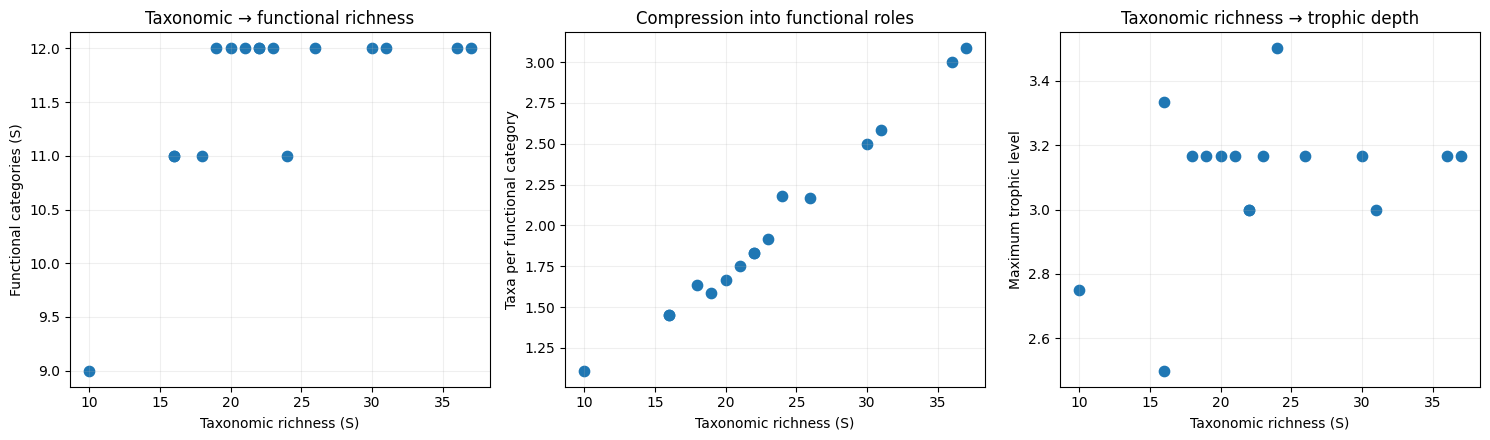

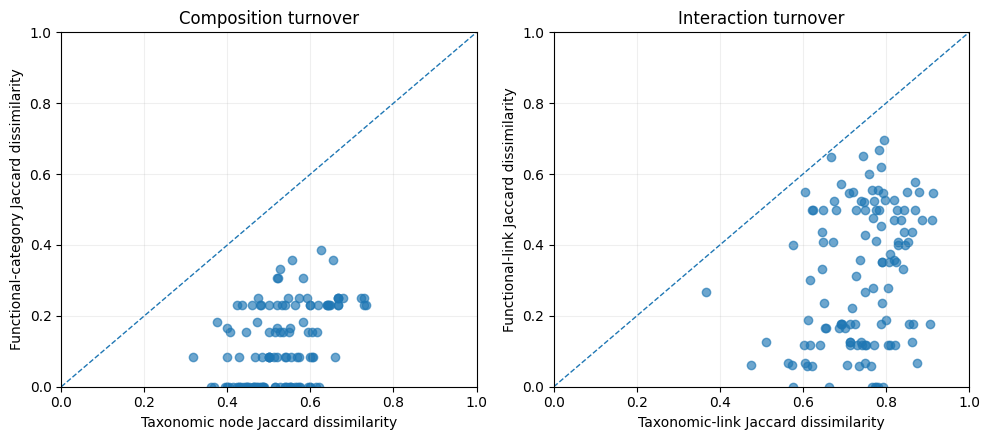

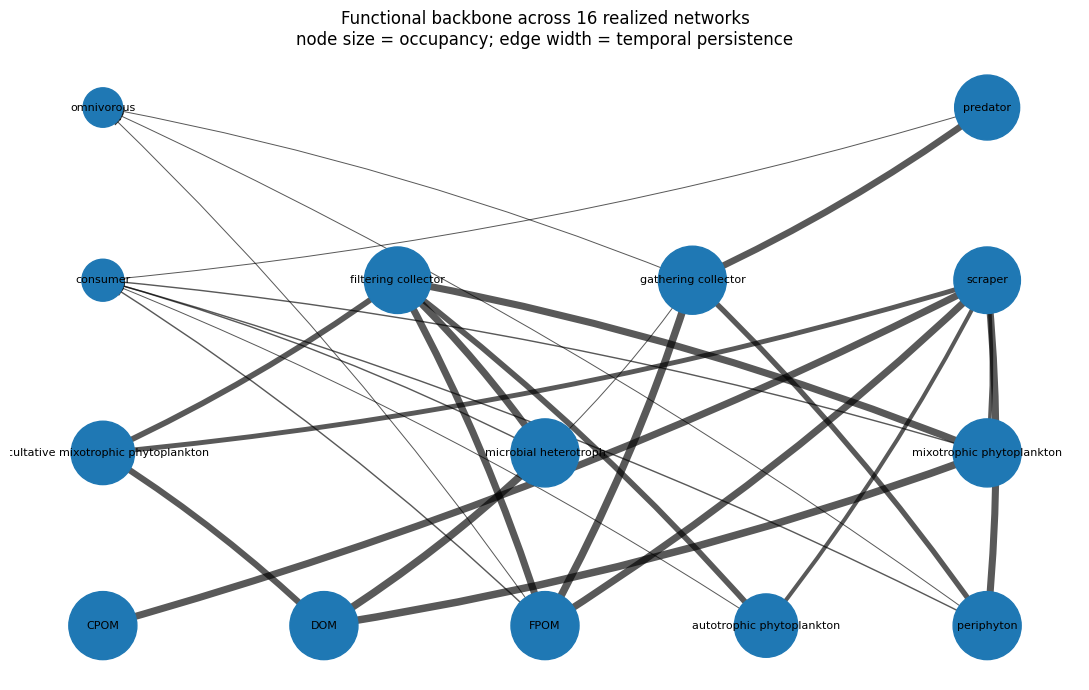

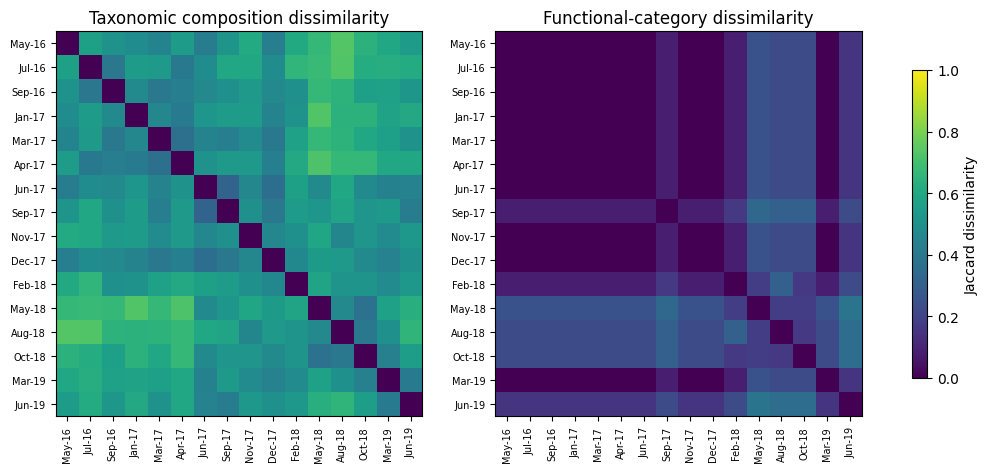

STAGE 4A — TAXONOMIC VARIABILITY -> FUNCTIONAL CONSTRAINT/CONVERGENCE
Dates: 16; pairwise comparisons: 120

DATE-LEVEL RANGES
S_tax: 10 – 37; mean=23.19; CV=0.317
S_func: 9 – 12; mean=11.56; CV=0.070
L_tax: 11 – 124; mean=48.38; CV=0.645
L_func_between: 9 – 18; mean=14.94; CV=0.165
taxa_per_functional_category: 1.111 – 3.083; mean=1.985; CV=0.283
tax_max_TL: 2.5 – 3.5; mean=3.099; CV=0.073
tax_max_chain_edges: 2 – 4; mean=2.75; CV=0.210

DATE-LEVEL ASSOCIATIONS
    x                            y  n  spearman_rho   spearman_p  kendall_tau    kendall_p  linear_slope_descriptive  linear_R2_descriptive
S_tax                       S_func 16      0.651751 6.227514e-03     0.563288 8.468372e-03                  0.071952               0.422208
S_tax               L_func_between 16      0.204647 4.470832e-01     0.177991 3.585676e-01                  0.145832               0.189531
S_tax taxa_per_functional_category 16      0.994100 6.567735e-15     0.966102 2.559058e-07                  0.0759

6987

In [11]:

# Stage 4A — Taxonomic variability -> functional constraint/convergence
# Laguna del Parque Unzué
#
# REQUIRED INPUTS (upload to /content in Google Colab):
# 1) FW_lagoon_nodes_AUDITED.csv
# 2) FW_lagoon_food_web_by_sampling_AUDITED.csv
# 3) FW_lagoon_trophic_links_AUDITED.csv
# 4) temporal_structural_observed_metrics_stage3_v31.csv
#
# No Stage-1 functional outputs are required: this notebook reconstructs the
# realized functional projection from the audited taxonomic data, using the
# same rule as functional_network_projection_stage1_v2.py.
#
# OUTPUTS:
# - stage4A_date_level_summary.csv
# - stage4A_pairwise_dissimilarity.csv
# - stage4A_functional_category_occupancy.csv
# - stage4A_functional_link_persistence.csv
# - stage4A_taxonomic_category_redundancy.csv
# - stage4A_association_summary.csv
# - stage4A_variability_summary.csv
# - stage4A_fig1_taxonomic_to_functional.png/pdf
# - stage4A_fig2_turnover_compression.png/pdf
# - stage4A_fig3_functional_backbone.png/pdf
# - stage4A_fig4_date_pair_heatmaps.png/pdf
# - stage4A_console_summary.txt

from pathlib import Path
import math, warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, kendalltau, linregress

warnings.filterwarnings("ignore", category=RuntimeWarning)

BASE = DATA_DIR

NODES_FILE = BASE / "FW_lagoon_nodes_AUDITED.csv"
SAMPLING_FILE = BASE / "FW_lagoon_food_web_by_sampling_AUDITED.csv"
TROPHIC_FILE = BASE / "FW_lagoon_trophic_links_AUDITED.csv"
STRUCT_METRICS_FILE = BASE / "temporal_structural_observed_metrics_stage3_v31.csv"

TEMPORAL_DATES = [
    "14/05/2016","09/07/2016","10/09/2016","20/01/2017",
    "16/03/2017","06/04/2017","29/06/2017","08/09/2017",
    "15/11/2017","23/12/2017","23/02/2018","19/05/2018",
    "11/08/2018","20/10/2018","09/03/2019","01/06/2019",
]

def clean(x):
    if pd.isna(x): return None
    x = str(x).strip()
    return x if x else None

def require(paths):
    missing=[p.name for p in paths if not p.exists()]
    if missing:
        raise FileNotFoundError(
            "Missing required files: " + ", ".join(missing) +
            f"\nUpload them to {BASE} and rerun."
        )

require([NODES_FILE,SAMPLING_FILE,TROPHIC_FILE,STRUCT_METRICS_FILE])

nodes=pd.read_csv(NODES_FILE)
sampling=pd.read_csv(SAMPLING_FILE)
trophic=pd.read_csv(TROPHIC_FILE)
sm=pd.read_csv(STRUCT_METRICS_FILE)

for c in ["node","category"]:
    nodes[c]=nodes[c].map(clean)
for c in ["consumer","resource"]:
    trophic[c]=trophic[c].map(clean)

if not {"node","category"}.issubset(nodes.columns):
    raise ValueError("Node table must contain node and category.")
if not {"consumer","resource"}.issubset(trophic.columns):
    raise ValueError("Trophic table must contain consumer and resource.")
if not set(TEMPORAL_DATES).issubset(sampling.columns):
    raise ValueError("Sampling table is missing one or more of the 16 complete dates.")
if "date" not in sm.columns:
    raise ValueError("Structural metrics table must contain date.")

node_to_cat=dict(zip(nodes["node"],nodes["category"]))
valid_taxa=set(node_to_cat)

def observed_taxa(date):
    s={clean(x) for x in sampling[date].dropna().tolist()}
    s.discard(None)
    unknown=s-valid_taxa
    if unknown: raise ValueError(f"{date}: unknown taxa {sorted(unknown)}")
    return s

def project_edges(taxa):
    tt=trophic[trophic.consumer.isin(taxa)&trophic.resource.isin(taxa)].copy()
    if tt.empty:
        return tt, set(), set()
    pairs=set()
    between=set()
    for r in tt.itertuples(index=False):
        rc=node_to_cat[r.resource]; cc=node_to_cat[r.consumer]
        pairs.add((rc,cc))
        if rc!=cc: between.add((rc,cc))
    return tt,pairs,between

def jaccard_distance(a,b):
    a=set(a); b=set(b)
    u=len(a|b)
    return np.nan if u==0 else 1-len(a&b)/u

# ---------- reconstruct 16 realized networks ----------
records=[]
taxa_by_date={}
cats_by_date={}
tax_edges_by_date={}
func_edges_by_date={}
func_all_edges_by_date={}

sm["date"]=sm["date"].astype(str).str.strip()
sm_idx=sm.set_index("date")

for d in TEMPORAL_DATES:
    taxa=observed_taxa(d)
    tt,fpairs,fbetween=project_edges(taxa)
    cats={node_to_cat[t] for t in taxa}
    taxa_by_date[d]=taxa
    cats_by_date[d]=cats
    tax_edges_by_date[d]=set(zip(tt["resource"],tt["consumer"]))
    func_edges_by_date[d]=fbetween
    func_all_edges_by_date[d]=fpairs

    row=sm_idx.loc[d]
    records.append({
        "date":d,
        "S_tax":len(taxa),
        "L_tax":len(tt),
        "S_func":len(cats),
        "L_func_between":len(fbetween),
        "L_func_including_within":len(fpairs),
        "n_within_category_pairs":len(fpairs-fbetween),
        "taxa_per_functional_category":len(taxa)/len(cats) if cats else np.nan,
        "functional_categories_per_taxon":len(cats)/len(taxa) if taxa else np.nan,
        "functional_node_compression":1-len(cats)/len(taxa) if taxa else np.nan,
        "functional_link_compression":1-len(fbetween)/len(tt) if len(tt) else np.nan,
        "tax_mean_TL":row.get("mean_trophic_level",np.nan),
        "tax_max_TL":row.get("max_trophic_level",np.nan),
        "tax_max_chain_edges":row.get("max_chain_edges",np.nan),
        "tax_connectance":row.get("connectance",np.nan),
        "tax_assortativity":row.get("out_in_degree_assortativity",np.nan),
        "tax_clustering":row.get("mean_directed_clustering",np.nan),
        "tax_transitivity":row.get("undirected_projection_transitivity",np.nan),
    })

date_df=pd.DataFrame(records)
date_df.to_csv(BASE/"stage4A_date_level_summary.csv",index=False)

# ---------- association summaries: descriptive effect sizes ----------
assoc=[]
pairs_to_test=[
    ("S_tax","S_func"),
    ("S_tax","L_func_between"),
    ("S_tax","taxa_per_functional_category"),
    ("S_tax","tax_max_TL"),
    ("S_tax","tax_max_chain_edges"),
    ("L_tax","L_func_between"),
]
for x,y in pairs_to_test:
    a=date_df[[x,y]].dropna()
    rho,p=spearmanr(a[x],a[y])
    tau,pt=kendalltau(a[x],a[y])
    lr=linregress(a[x],a[y])
    assoc.append({"x":x,"y":y,"n":len(a),"spearman_rho":rho,"spearman_p":p,
                  "kendall_tau":tau,"kendall_p":pt,
                  "linear_slope_descriptive":lr.slope,"linear_R2_descriptive":lr.rvalue**2})
assoc_df=pd.DataFrame(assoc)
assoc_df.to_csv(BASE/"stage4A_association_summary.csv",index=False)

# ---------- variability/compression ----------
varrows=[]
for v in ["S_tax","L_tax","S_func","L_func_between","tax_max_TL","tax_max_chain_edges",
          "taxa_per_functional_category"]:
    x=pd.to_numeric(date_df[v],errors="coerce").dropna()
    varrows.append({"variable":v,"n":len(x),"min":x.min(),"max":x.max(),
                    "mean":x.mean(),"sd":x.std(ddof=1),
                    "CV":x.std(ddof=1)/x.mean() if x.mean()!=0 else np.nan,
                    "max_min_ratio":x.max()/x.min() if x.min()!=0 else np.nan})
pd.DataFrame(varrows).to_csv(BASE/"stage4A_variability_summary.csv",index=False)

# ---------- 120 pairwise comparisons ----------
pairrows=[]
for i,d1 in enumerate(TEMPORAL_DATES):
    for d2 in TEMPORAL_DATES[i+1:]:
        pairrows.append({
            "date1":d1,"date2":d2,
            "taxonomic_node_dissimilarity":jaccard_distance(taxa_by_date[d1],taxa_by_date[d2]),
            "taxonomic_link_dissimilarity":jaccard_distance(tax_edges_by_date[d1],tax_edges_by_date[d2]),
            "functional_category_dissimilarity":jaccard_distance(cats_by_date[d1],cats_by_date[d2]),
            "functional_link_dissimilarity":jaccard_distance(func_edges_by_date[d1],func_edges_by_date[d2]),
        })
pair_df=pd.DataFrame(pairrows)
pair_df["node_dissimilarity_compression"]=pair_df["taxonomic_node_dissimilarity"]-pair_df["functional_category_dissimilarity"]
pair_df["link_dissimilarity_compression"]=pair_df["taxonomic_link_dissimilarity"]-pair_df["functional_link_dissimilarity"]
pair_df.to_csv(BASE/"stage4A_pairwise_dissimilarity.csv",index=False)

# Mantel-like correlation is NOT tested with naive p because pairwise distances are non-independent.
# Report rho as descriptive only; formal permutation test could be added later if needed.
rho_nodes,_=spearmanr(pair_df.taxonomic_node_dissimilarity,pair_df.functional_category_dissimilarity)
rho_links,_=spearmanr(pair_df.taxonomic_link_dissimilarity,pair_df.functional_link_dissimilarity)

# ---------- category occupancy ----------
catrows=[]
for cat in sorted(nodes.category.dropna().unique()):
    dates=[d for d in TEMPORAL_DATES if cat in cats_by_date[d]]
    tax_counts=[sum(node_to_cat[t]==cat for t in taxa_by_date[d]) for d in TEMPORAL_DATES]
    catrows.append({
        "functional_category":cat,
        "n_dates_present":len(dates),
        "occupancy":len(dates)/len(TEMPORAL_DATES),
        "mean_taxa_when_present":np.mean([x for x in tax_counts if x>0]) if any(x>0 for x in tax_counts) else 0,
        "max_taxa_in_category":max(tax_counts),
        "dates_present":" | ".join(dates)
    })
cat_df=pd.DataFrame(catrows).sort_values(["occupancy","functional_category"],ascending=[False,True])
cat_df.to_csv(BASE/"stage4A_functional_category_occupancy.csv",index=False)

# ---------- within-category taxonomic multiplicity by date ----------
redrows=[]
for d in TEMPORAL_DATES:
    for cat in sorted(cats_by_date[d]):
        members=sorted(t for t in taxa_by_date[d] if node_to_cat[t]==cat)
        redrows.append({"date":d,"functional_category":cat,"n_taxa":len(members),
                        "taxa":" | ".join(members)})
pd.DataFrame(redrows).to_csv(BASE/"stage4A_taxonomic_category_redundancy.csv",index=False)

# ---------- functional link persistence ----------
all_func_edges=sorted(set().union(*func_edges_by_date.values()))
linkrows=[]
for e in all_func_edges:
    dates=[d for d in TEMPORAL_DATES if e in func_edges_by_date[d]]
    linkrows.append({"resource_category":e[0],"consumer_category":e[1],
                     "n_dates_realized":len(dates),
                     "persistence":len(dates)/len(TEMPORAL_DATES),
                     "dates_realized":" | ".join(dates)})
link_df=pd.DataFrame(linkrows).sort_values(["persistence","resource_category","consumer_category"],
                                          ascending=[False,True,True])
link_df.to_csv(BASE/"stage4A_functional_link_persistence.csv",index=False)

# ---------- Figure 1: taxonomic expansion -> functional expansion ----------
fig,axs=plt.subplots(1,3,figsize=(15,4.5))
axs[0].scatter(date_df.S_tax,date_df.S_func,s=55)
axs[0].set(xlabel="Taxonomic richness (S)",ylabel="Functional categories (S)",
           title="Taxonomic → functional richness")
axs[1].scatter(date_df.S_tax,date_df.taxa_per_functional_category,s=55)
axs[1].set(xlabel="Taxonomic richness (S)",ylabel="Taxa per functional category",
           title="Compression into functional roles")
axs[2].scatter(date_df.S_tax,date_df.tax_max_TL,s=55)
axs[2].set(xlabel="Taxonomic richness (S)",ylabel="Maximum trophic level",
           title="Taxonomic richness → trophic depth")
for ax in axs: ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(BASE/"stage4A_fig1_taxonomic_to_functional.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4A_fig1_taxonomic_to_functional.pdf",bbox_inches="tight")
plt.show()

# ---------- Figure 2: pairwise turnover compression ----------
fig,axs=plt.subplots(1,2,figsize=(10,4.5))
axs[0].scatter(pair_df.taxonomic_node_dissimilarity,pair_df.functional_category_dissimilarity,alpha=.65)
axs[0].plot([0,1],[0,1],"--",linewidth=1)
axs[0].set(xlim=(0,1),ylim=(0,1),xlabel="Taxonomic node Jaccard dissimilarity",
           ylabel="Functional-category Jaccard dissimilarity",
           title="Composition turnover")
axs[1].scatter(pair_df.taxonomic_link_dissimilarity,pair_df.functional_link_dissimilarity,alpha=.65)
axs[1].plot([0,1],[0,1],"--",linewidth=1)
axs[1].set(xlim=(0,1),ylim=(0,1),xlabel="Taxonomic-link Jaccard dissimilarity",
           ylabel="Functional-link Jaccard dissimilarity",
           title="Interaction turnover")
for ax in axs: ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(BASE/"stage4A_fig2_turnover_compression.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4A_fig2_turnover_compression.pdf",bbox_inches="tight")
plt.show()

# ---------- Figure 3: functional backbone ----------
G=nx.DiGraph()
for r in cat_df.itertuples():
    G.add_node(r.functional_category,occupancy=r.occupancy)
for r in link_df.itertuples():
    G.add_edge(r.resource_category,r.consumer_category,persistence=r.persistence)

# trophic-like layout from cumulative loop-free functional graph
basal=[n for n in G.nodes if G.in_degree(n)==0]
try:
    generations=list(nx.topological_generations(G))
    level={n:i for i,g in enumerate(generations) for n in g}
except nx.NetworkXUnfeasible:
    level={n:0 for n in G.nodes}
levels={}
for n,l in level.items(): levels.setdefault(l,[]).append(n)
pos={}
for l,ns in sorted(levels.items()):
    ns=sorted(ns)
    xs=np.linspace(-1,1,len(ns)) if len(ns)>1 else [0]
    for x,n in zip(xs,ns): pos[n]=(x,l)

fig,ax=plt.subplots(figsize=(11,7))
node_sizes=[700+1700*G.nodes[n]["occupancy"] for n in G.nodes]
edge_widths=[0.4+5*G.edges[e]["persistence"] for e in G.edges]
nx.draw_networkx_nodes(G,pos,node_size=node_sizes,ax=ax)
nx.draw_networkx_labels(G,pos,font_size=8,ax=ax)
nx.draw_networkx_edges(G,pos,width=edge_widths,arrows=True,arrowstyle="-|>",arrowsize=14,
                       connectionstyle="arc3,rad=0.05",alpha=.65,ax=ax)
ax.set_title("Functional backbone across 16 realized networks\nnode size = occupancy; edge width = temporal persistence")
ax.axis("off")
fig.tight_layout()
fig.savefig(BASE/"stage4A_fig3_functional_backbone.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4A_fig3_functional_backbone.pdf",bbox_inches="tight")
plt.show()

# ---------- Figure 4: date-pair heatmaps (visual only) ----------
def dist_matrix(mapping):
    n=len(TEMPORAL_DATES); M=np.zeros((n,n))
    for i,a in enumerate(TEMPORAL_DATES):
        for j,b in enumerate(TEMPORAL_DATES):
            M[i,j]=jaccard_distance(mapping[a],mapping[b])
    return M

Mt=dist_matrix(taxa_by_date)
Mf=dist_matrix(cats_by_date)
fig,axs=plt.subplots(1,2,figsize=(13,5))
im0=axs[0].imshow(Mt,vmin=0,vmax=1,aspect="auto")
axs[0].set_title("Taxonomic composition dissimilarity")
im1=axs[1].imshow(Mf,vmin=0,vmax=1,aspect="auto")
axs[1].set_title("Functional-category dissimilarity")
labels=[pd.to_datetime(d,dayfirst=True).strftime("%b-%y") for d in TEMPORAL_DATES]
for ax in axs:
    ax.set_xticks(range(16)); ax.set_xticklabels(labels,rotation=90,fontsize=7)
    ax.set_yticks(range(16)); ax.set_yticklabels(labels,fontsize=7)
fig.colorbar(im1,ax=axs.ravel().tolist(),label="Jaccard dissimilarity",shrink=.8)
fig.savefig(BASE/"stage4A_fig4_date_pair_heatmaps.png",dpi=300,bbox_inches="tight")
fig.savefig(BASE/"stage4A_fig4_date_pair_heatmaps.pdf",bbox_inches="tight")
plt.show()

# ---------- concise console report ----------
lines=[]
lines.append("STAGE 4A — TAXONOMIC VARIABILITY -> FUNCTIONAL CONSTRAINT/CONVERGENCE")
lines.append("="*78)
lines.append(f"Dates: {len(TEMPORAL_DATES)}; pairwise comparisons: {len(pair_df)}")
lines.append("")
lines.append("DATE-LEVEL RANGES")
for v in ["S_tax","S_func","L_tax","L_func_between","taxa_per_functional_category",
          "tax_max_TL","tax_max_chain_edges"]:
    x=date_df[v].dropna()
    lines.append(f"{v}: {x.min():.4g} – {x.max():.4g}; mean={x.mean():.4g}; CV={x.std(ddof=1)/x.mean():.3f}")
lines.append("")
lines.append("DATE-LEVEL ASSOCIATIONS")
lines.append(assoc_df.to_string(index=False))
lines.append("")
lines.append("PAIRWISE TURNOVER (120 non-independent pairs; rho descriptive only)")
lines.append(f"Taxonomic node vs functional-category dissimilarity: rho={rho_nodes:.3f}")
lines.append(f"Taxonomic link vs functional-link dissimilarity: rho={rho_links:.3f}")
lines.append(f"Mean taxonomic node dissimilarity: {pair_df.taxonomic_node_dissimilarity.mean():.3f}")
lines.append(f"Mean functional-category dissimilarity: {pair_df.functional_category_dissimilarity.mean():.3f}")
lines.append(f"Mean node->function compression (difference): {pair_df.node_dissimilarity_compression.mean():.3f}")
lines.append(f"Mean taxonomic-link dissimilarity: {pair_df.taxonomic_link_dissimilarity.mean():.3f}")
lines.append(f"Mean functional-link dissimilarity: {pair_df.functional_link_dissimilarity.mean():.3f}")
lines.append(f"Mean link->function compression (difference): {pair_df.link_dissimilarity_compression.mean():.3f}")
lines.append("")
lines.append("FUNCTIONAL CATEGORY OCCUPANCY")
lines.append(cat_df[["functional_category","n_dates_present","occupancy","mean_taxa_when_present","max_taxa_in_category"]].to_string(index=False))
lines.append("")
lines.append("MOST PERSISTENT FUNCTIONAL LINKS")
lines.append(link_df[["resource_category","consumer_category","n_dates_realized","persistence"]].head(25).to_string(index=False))
lines.append("")
lines.append("INTERPRETATION RULES")
lines.append("- Do not treat the 120 pairwise distances as independent observations.")
lines.append("- Pairwise Spearman rho is descriptive here; do not use its naive p-value.")
lines.append("- Higher taxonomic than functional dissimilarity supports compression/convergence descriptively.")
lines.append("- Similar functional architecture does not by itself demonstrate resilience or compensatory functioning.")
lines.append("- Functional links are binary potential/realized-by-cooccurrence pathways, not measured energy flux.")
report="\n".join(lines)
print(report)
(BASE/"stage4A_console_summary.txt").write_text(report,encoding="utf-8")
